# Time series forecasting

In [4]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
## para declarar una rnn donde el output del timestep anterior es para entrenar al siguiente timestep (simplernn)
tf.keras.layers.SimpleRNN(
    units, ## units tamaño del vector que se calcula en la capa de concurrencia (vector h) 
    dropout=0.0,
    recurrent_dropout = 0.0,
    return_sequences = False, # luego se explica
    return_state=False, # se vera en otro notebook pero es importante
    go_backards=False,
    stateful = False
)

## para declarar una rnn con GRU
tf.keras.layers.GRU(
    units, ## units tamaño del vector que se calcula en la capa de concurrencia (vector h) 
    dropout=0.0,
    recurrent_dropout = 0.0,
    return_sequences = False, # luego se explica
    return_state=False, # se vera en otro notebook pero es importante
    go_backards=False,
    stateful = False
)
## para declarar una rnn con LSTM
tf.keras.layers.LSTM(
    units, ## units tamaño del vector que se calcula en la capa de concurrencia (vector h) 
    dropout=0.0,
    recurrent_dropout = 0.0,
    return_sequences = False, # luego se explica
    return_state=False, # se vera en otro notebook pero es importante
    go_backards=False,
    stateful = False
)

NameError: name 'units' is not defined

In [6]:
# dims of input: [batch, timesteps, features]
inputs = tf.random.normal([32,10,4])
print('input dim (batch, timesteps, feature) :', inputs.shape)
# return_sequences=False, return_state = False
lstm = tf.keras.layers.LSTM(units=2)
output = lstm(inputs)
print('return_state=False output shape: ', output.shape)

input dim (batch, timesteps, feature) : (32, 10, 4)
return_state=False output shape:  (32, 2)


In [ ]:


## para crear una tred neuronal profunda necesitariamos aplicar muchas capas internas. Ejemplo:

timesteps = 10
features =8 # dimensionof the input of every cell

# shape [batch, timesteps, features]

inputs = tf.keras.Input(shape=(timesteps, features), name = 'input')
lstm_1 = layers.LSTM(64, return_sequences=True, name= 'lstm_1')(inputs)
lstm_2 = layers.LSTM(64, return_sequences=True, name='lstm_2')(lstm_1)
# last lstm layer: depends in [one to many or many to many] (por ahora esta es many to one (por lo tanto se pone en false el return_sequences))
lstm_3 = layers.LSTM(64,return_sequences=False, name='lstm_3')(lstm_2)
model = keras.Model(inputs=inputs, outputs=lstm_3,name='rnn Example')

inputs = tf.random.normal([32,timesteps,features])
print(model(inputs).shape)


(32, 64)


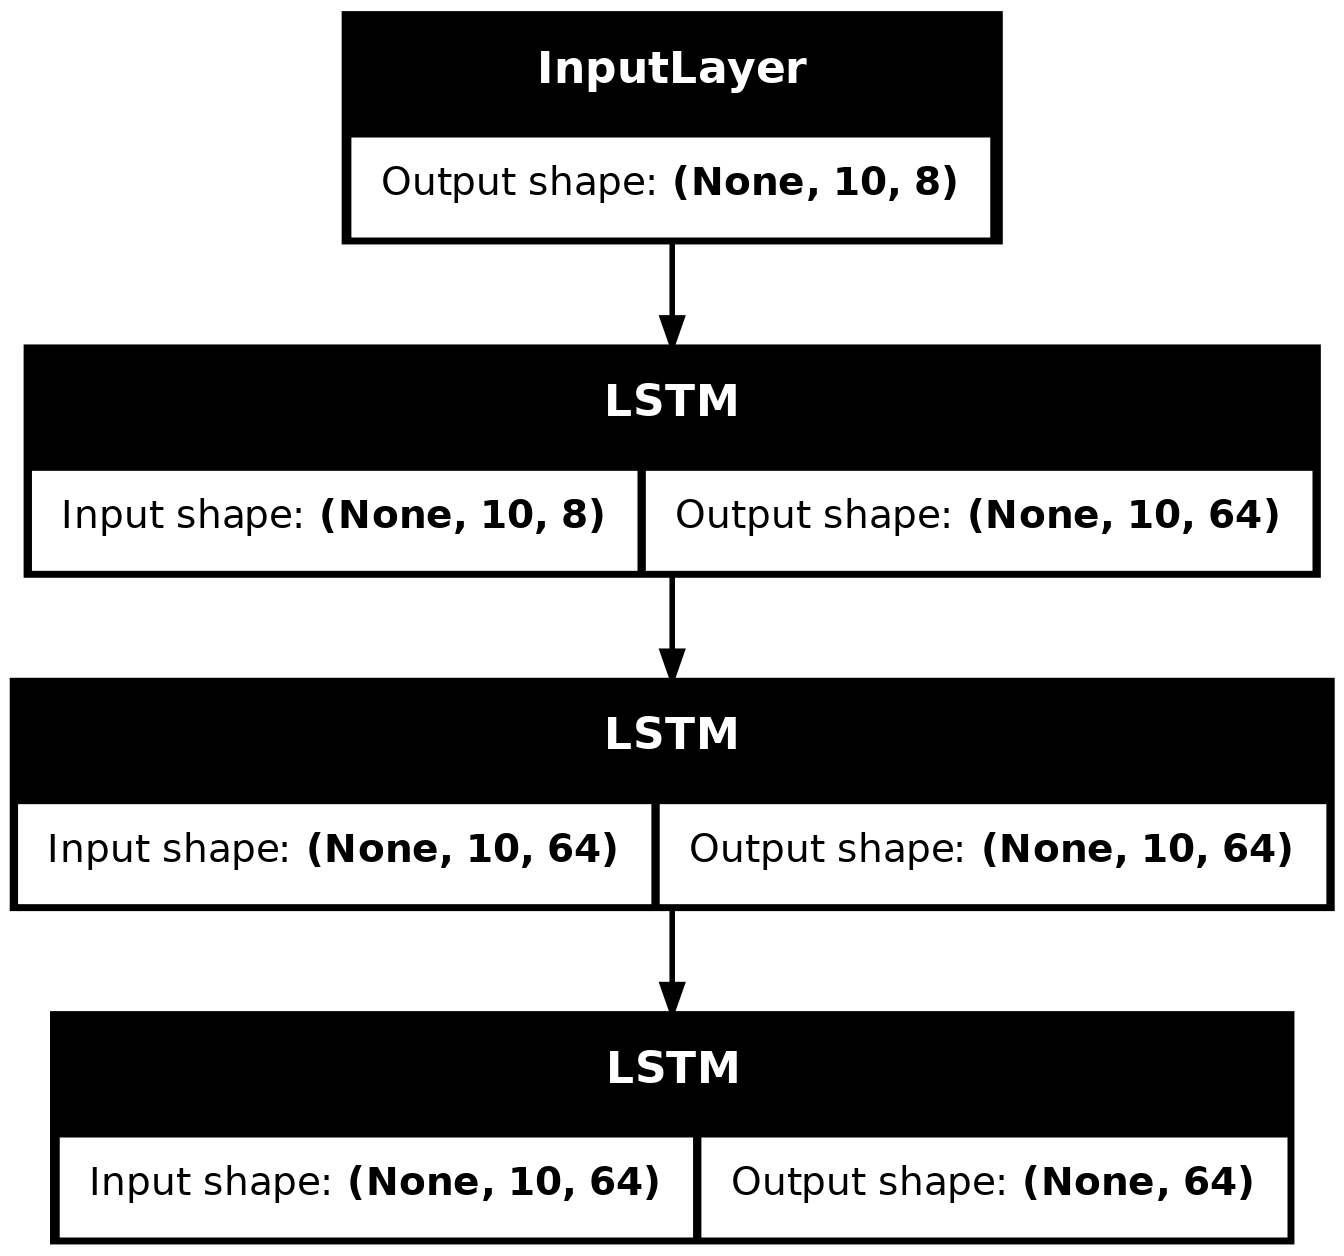

In [8]:
from tensorflow.keras.utils import plot_model
plot_model(model, show_shapes = True)    

In [9]:
# vamos a ver como hacer un modelo bidireccional
model = keras.Sequential()

# if we create a second layer it must be set return_sequency=True
model.add(
    layers.Bidirectional(layers.LSTM(64, return_sequences=True), input_shape= (timesteps,features))
)
model.add(layers.Bidirectional(layers.LSTM(32)))
# output
model.add(layers.Dense(10))
model.summary()

/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/layers/rnn/bidirectional.py:110: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 10, 128)        │        37,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,242 (309.54 KB)

 Trainable params: 79,242 (309.54 KB)

 Non-trainable params: 0 (0.00 B)

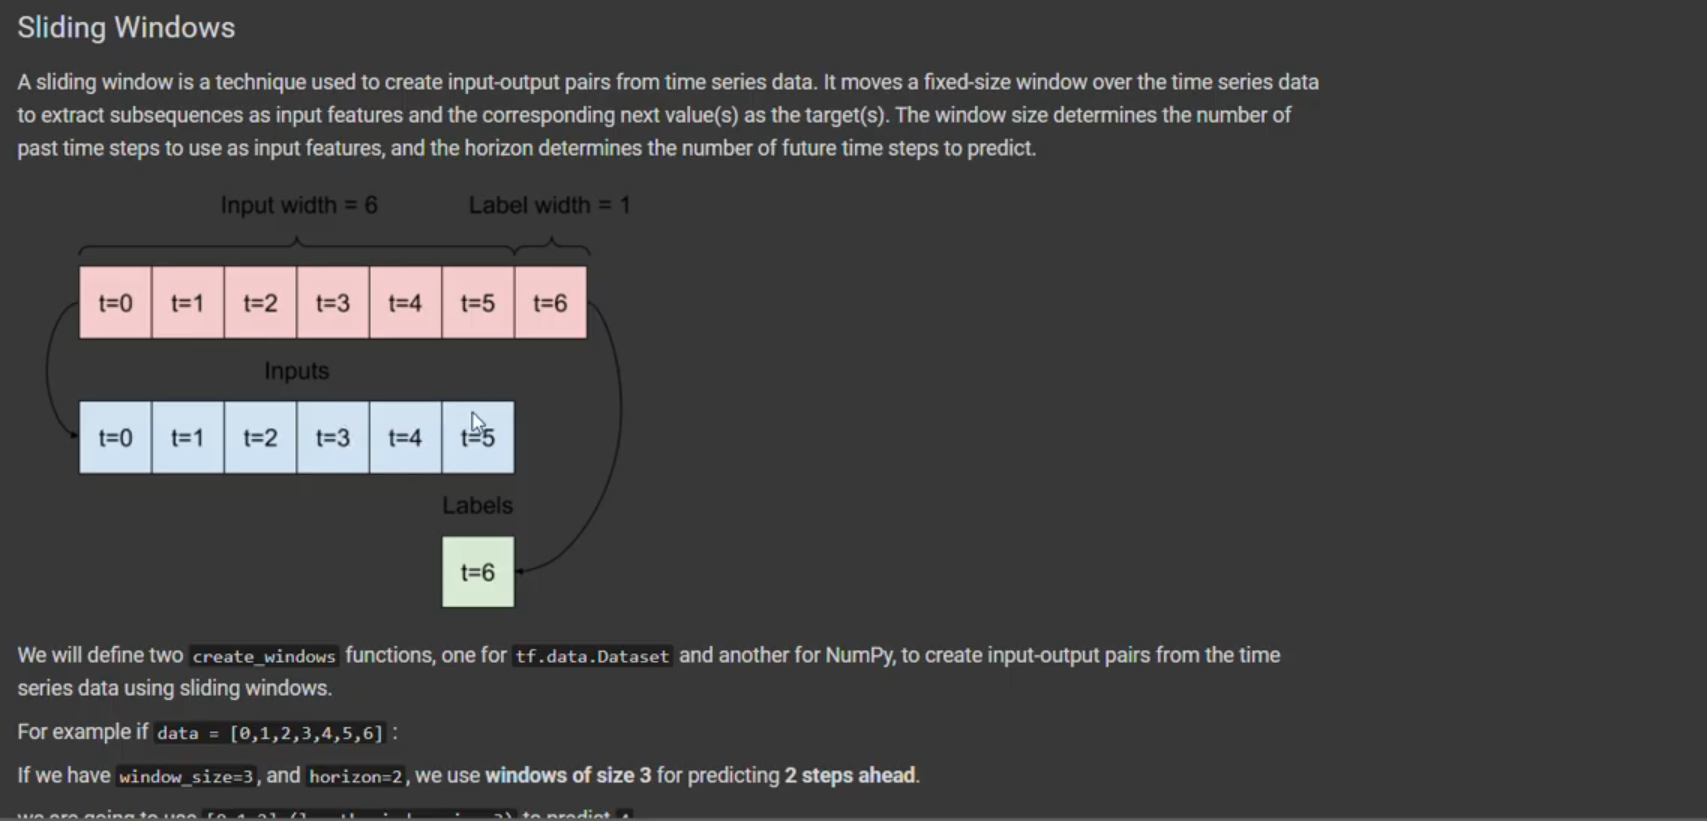

In [10]:
def create_windows_np(data, window_size, horizon, shuffle=False):
    """
    Creates a dataset from the given time series data using NumPy.
    
    Parameters:
    data (np.ndarray): Time series data with one dimension.
    window_size (int): The number of past time steps to use as input features.
    horizon (int): The number of future time steps to predict.
    shuffle (bool): Shuffle the windows or not.
    
    Returns:
    tuple: A tuple containing the input-output pairs (windows, targets) as NumPy arrays.
    """

    X, y = [], []
    for i in range(len(data) - window_size - horizon + 1):
        X.append(data[i:i+window_size])
        y.append(data[i+window_size+horizon-1])

    X, y = np.array(X), np.array(y)
    
    if shuffle:
        indices = np.arange(len(X))
        np.random.shuffle(indices)
        X, y = X[indices], y[indices]
    
    return X, y

In [11]:


X_trial, y_trial = create_windows_np(np.array([0, 1, 2, 3, 4, 5, 6]),
                                     window_size=3,
                                     horizon=2,
                                     shuffle=False)
for ind in range(len(y_trial)):
    print(X_trial[ind, :], y_trial[ind])



[0 1 2] 4
[1 2 3] 5
[2 3 4] 6


In [12]:
def create_windows_tf(data, window_size, horizon, shuffle=False):
    """
    Creates a dataset from the given time series data using tf.data.Dataset.
    
    Parameters:
    data (np.ndarray): Time series data with with one dimension.
    window_size (int): The number of past time steps to use as input features.
    horizon (int): The number of future time steps to predict.
    shuffle (bool): Whether to shuffle the data or not.
    
    Returns:
    tf.data.Dataset: The resulting dataset.
    """  
    ts_data = tf.data.Dataset.from_tensor_slices(data)
    ts_data = ts_data.window(window_size + horizon, shift=1, drop_remainder=True)
    ts_data = ts_data.flat_map(lambda window: window.batch(window_size + horizon))
    ts_data = ts_data.map(lambda window: (window[:window_size], window[-1]))
    if shuffle:
        ts_data = ts_data.shuffle(buffer_size=data.shape[0])
    return ts_data

ts_dataset = create_windows_tf(np.array([0, 1, 2, 3, 4, 5, 6]),
                                     window_size=3,
                                     horizon=2,
                                     shuffle=False)

for window, target in ts_dataset:
    print(window.numpy(), target.numpy())

[0 1 2] 4
[1 2 3] 5
[2 3 4] 6


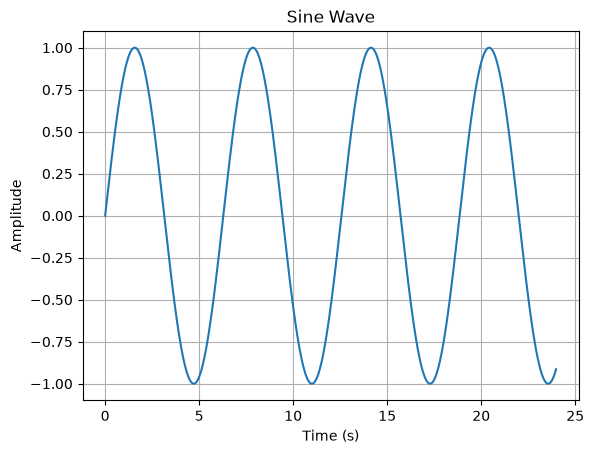

In [ ]:
### como primer ejemplo vamos a ver para crear un modelo para predecir el coseno que es super predecible

# Generate sine wave data
t = np.arange(0, 24, 0.02)
y = np.sin(t)

# Plot the sine wave
plt.plot(t, y)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Sine Wave')
plt.grid(True)
plt.show()



In [ ]:

# dividimos datos en train test
# train test split
train_size = int(len(y) * 0.8)
ts_train, ts_test = y[:train_size], y[train_size:]
print(ts_test.shape)



(240,)


In [ ]:
# creamos las ventanas de train y test y asi tenemos distintas ventanas para el mdoelo
window_size = 10
horizon = 10
X_train, y_train = create_windows_np(ts_train, window_size, horizon=2, shuffle=True)
X_test, y_test = create_windows_np(ts_test, window_size, horizon=2, shuffle=False)

print(f'Train shape: {X_train.shape}') # vemos que tenemos 949 ventanas para trin y 229 para test y 10 el tamaño de la ventana- es decir que hemos creado secuencias de longitud 10 tanto para train como para test
print(f'Test shape: {X_test.shape}')

Train shape: (949, 10)
Test shape: (229, 10)


In [ ]:

# creamos el modelo y lo entrenamos (el modelo lo creamos con lstm)
inputs_shape = (window_size, 1)

# Define input shape and number of time steps
inputs = keras.layers.Input(shape=(window_size, 1))

# Define LSTM layer with a certain number of units
lstm_out_1 = keras.layers.LSTM(8, return_sequences=False)(inputs)

# Define output layer with a single unit
outputs = keras.layers.Dense(1)(lstm_out_1) # como estamos prediciendo valores numericos la ultima capa sera una capa densa con una unica neurona y la funcion de activacion lineal

model = keras.Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=keras.optimizers.Adam(), loss="mse")
model.summary()

history = model.fit(
    X_train, y_train,
    epochs=7,
    validation_data=(X_test, y_test)
)



Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 10, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 8)              │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 329 (1.29 KB)

 Trainable params: 329 (1.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/7
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 57ms/step - loss: 0.3132 - val_loss: 0.2484
Epoch 2/7
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1334 - val_loss: 0.0820
Epoch 3/7
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0357 - val_loss: 0.0166
Epoch 4/7
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0104 - val_loss: 0.0067
Epoch 5/7
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0085 - val_loss: 0.0062
Epoch 6/7
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0081 - val_loss: 0.0063
Epoch 7/7
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0078 - val_loss: 0.0061


In [17]:


# Use the trained RNN model to make predictions on the test data.
y_pred = model.predict(X_test)



8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


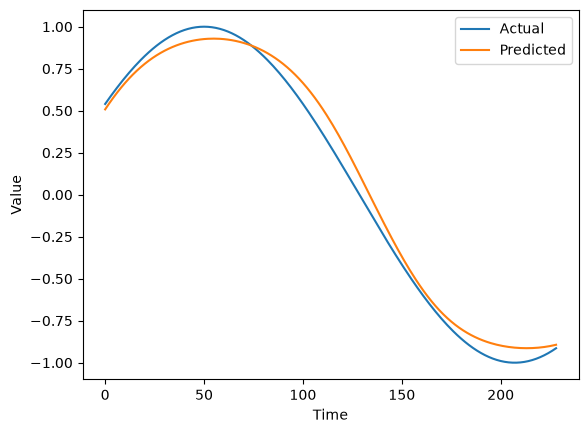

In [ ]:
# terminamos comparando el actual con el predicho
# visualize the actual vs. predicted values.
plt.plot(y_test, label='Actual')
plt.plot(y_pred, label='Predicted')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()
# mas o menos vemos que el modelo acierta pero no es 100% exacta y tenemos q tener en cuenta qu ela red neurnal es muy sencilla compuesta por una unica capa y con bastante poca chicha


In [19]:
# vamos a ver ahora el mismo procesocon multivariante
import pandas as pd


def create_windows_multivariate_np(data, window_size, horizon, target_col_idx, shuffle=False):
    """
    Creates a dataset from the given time series data using NumPy.

    Parameters:
    data (np.ndarray or pd.DataFrame): Time series data with multiple features.
    window_size (int): The number of past time steps to use as input features.
    horizon (int): The number of future time steps to predict.
    target_col_idx (int): The index of the target column in the input data.
    shuffle (bool): Whether to shuffle the data or not.

    Returns:
    tuple: A tuple containing the input-output pairs (X, y) as NumPy arrays.
    """
    if isinstance(data, pd.DataFrame):
        data = data.values

    X, y = [], []
    for i in range(len(data) - window_size - horizon + 1):
        X.append(data[i:i+window_size, :])
        y.append(data[i+window_size+horizon-1, target_col_idx])

    X, y = np.array(X), np.array(y)

    if shuffle:
        indices = np.arange(X.shape[0])
        np.random.shuffle(indices)
        X, y = X[indices], y[indices]

    return X, y


def create_windows_multivariate_tf(data, window_size, horizon, target_col_idx, shuffle=False):
    """
    Creates a dataset from the given time series data using tf.data.Dataset.

    Parameters:
    data (pd.DataFrame): Time series data with multiple features.
    window_size (int): The number of past time steps to use as input features.
    horizon (int): The number of future time steps to predict.
    target_col_idx (int): The index of the target column in the input data.
    shuffle (bool): Whether to shuffle the data or not.

    Returns:
    tf.data.Dataset: The resulting dataset.
    """
    if isinstance(data, pd.DataFrame):
        data = data.values
    
    ts_data = tf.data.Dataset.from_tensor_slices(data)
    ts_data = ts_data.window(window_size + horizon, shift=1, drop_remainder=True)
    ts_data = ts_data.flat_map(lambda window: window.batch(window_size + horizon))
    ts_data = ts_data.map(lambda window: (
        window[:window_size], window[-1, target_col_idx]))
    if shuffle:
        ts_data = ts_data.shuffle(buffer_size=data.shape[0])
    return ts_data

In [ ]:


# Generate synthetic multivariate time series data
t = np.arange(0, 24, 0.01)
y1 = np.sin(0.1 * t) # aqui definicimos dos series temporales. las dos con de tipo seno con disitnta frecuencia  y amplitud pero son para probar
y2 = 0.5 * np.sin(0.2 * t)
data = np.vstack((y1, y2)).T
print(data.shape)



(2400, 2)


In [21]:


# train test split
train_size = int(data.shape[0] * 0.8)
ts_train, ts_test = data[:train_size], data[train_size:]
print(ts_test.shape)



(480, 2)


In [22]:


window_size = 10
horizon = 10


train_ds = create_windows_multivariate_tf(
    ts_train, window_size, horizon, target_col_idx=0, shuffle=True)

test_ds = create_windows_multivariate_tf(
    ts_test, window_size, horizon, target_col_idx=0, shuffle=False)

train_ds = train_ds.batch(64)
test_ds = test_ds.batch(100)



In [23]:
for window, target in train_ds:
    print(window.numpy().shape, target.numpy().shape)
    break

(64, 10, 2) (64,)


In [ ]:


num_features = 2 # (y1, y2) # lo principal que cambia aqui es q ahora la entrada va a estar compuesta por dos variables (dos señales)

# Define input shape and number of time steps
inputs = keras.layers.Input(shape=(window_size, num_features))

# Define LSTM layer with a certain number of units
lstm_out_1 = keras.layers.LSTM(8, return_sequences=False)(inputs)

# Define output layer with a single unit
outputs = keras.layers.Dense(1)(lstm_out_1)

model = keras.Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=keras.optimizers.Adam(), loss="mse")
model.summary()

history = model.fit(
    train_ds,
    epochs=12,
    validation_data=test_ds
)



Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 10, 2)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 8)              │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361 (1.41 KB)

 Trainable params: 361 (1.41 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/12


/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0672 - val_loss: 0.1441
Epoch 2/12
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0278 - val_loss: 0.0733
Epoch 3/12
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0105 - val_loss: 0.0184
Epoch 4/12
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0019 - val_loss: 0.0012
Epoch 5/12
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 2.0769e-04 - val_loss: 1.4310e-04
Epoch 6/12
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.6431e-04 - val_loss: 1.8750e-04
Epoch 7/12
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.4302e-04 - val_loss: 1.8764e-04
Epoch 8/12
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.2596e-04 - val_loss: 1.5417e-04
Epoch 9/12
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.1053e-04 - val_loss: 1.5873e-04
Epoch 10/12
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 9.6134e-05 - val_loss: 1.6340e-04
Epoch 11/12
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 8.4017e-05 - val_loss: 1.6088e-04
Epoch 12/12
30/30 ━━━━━━━━━━

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step 


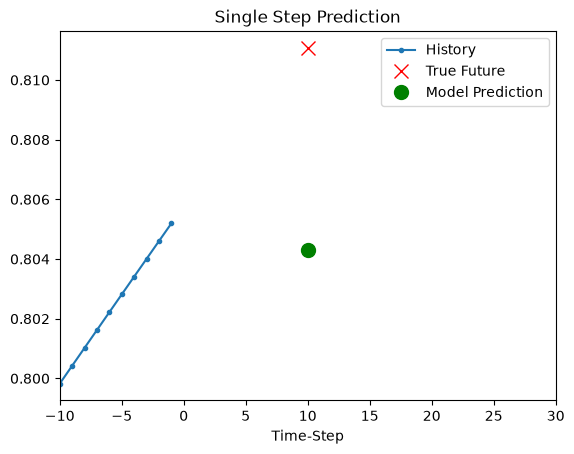

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


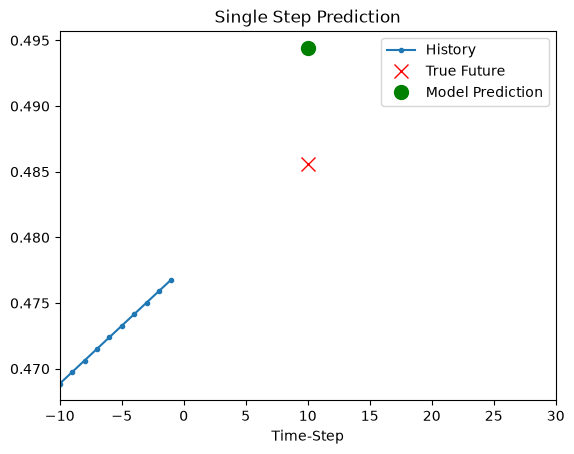

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


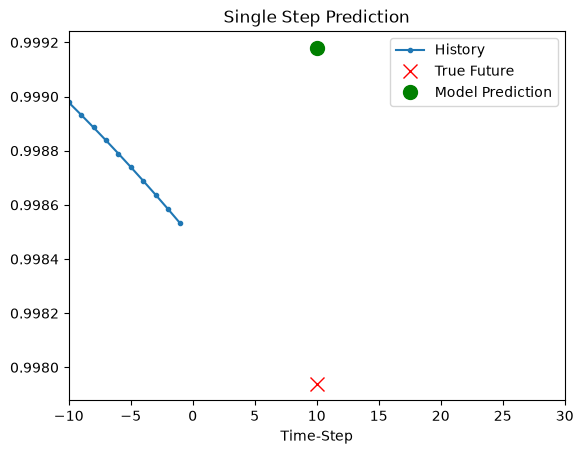

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


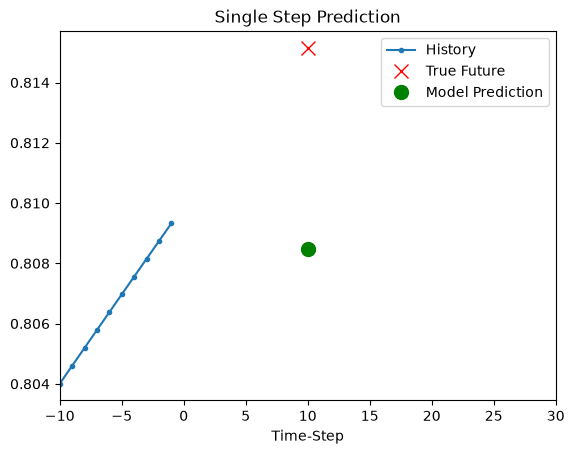

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


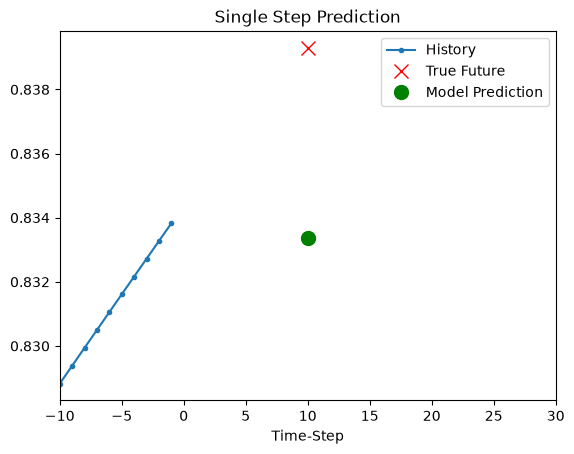

In [ ]:


def show_plot(plot_data, delta, title):
    labels = ["History", "True Future", "Model Prediction"]
    marker = [".-", "rx", "go"]
    time_steps = list(range(-(plot_data[0].shape[0]), 0))
    if delta:
        future = delta
    else:
        future = 0

    plt.title(title)
    for i, val in enumerate(plot_data):
        if i:
            plt.plot(future, plot_data[i], marker[i], markersize=10, label=labels[i])
        else:
            plt.plot(time_steps, plot_data[i].flatten(), marker[i], label=labels[i])
    plt.legend()
    plt.xlim([time_steps[0], (future + 5) * 2])
    plt.xlabel("Time-Step")
    plt.show()
    return


for x, y in train_ds.take(5):
    x_in = x.numpy()
    y_in = y.numpy().flatten()
    pred = model.predict(x)
    show_plot(
        [x_in[0,:, 0], y_in[0], pred.flatten()[0]],
        horizon,
        "Single Step Prediction",
    )

## esta funcion sirve para ver el decalaje que esta habiendo entre el valor que el modelo precide con el real y con los datos introducidos


batch:  0
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


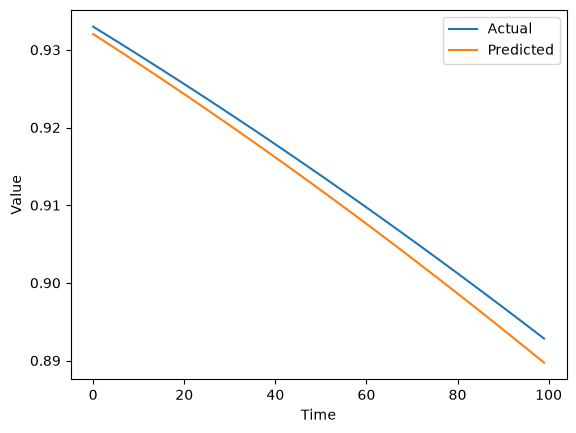

batch:  1
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


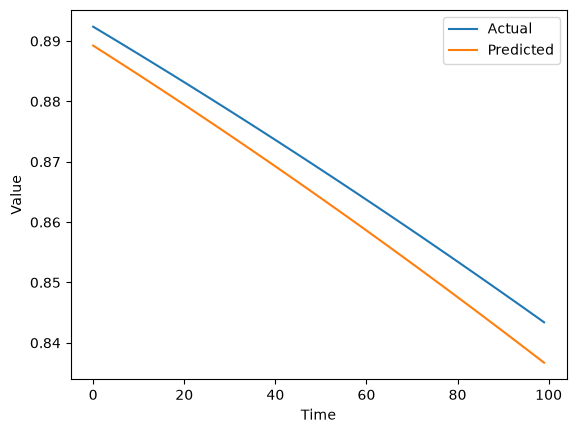

batch:  2
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


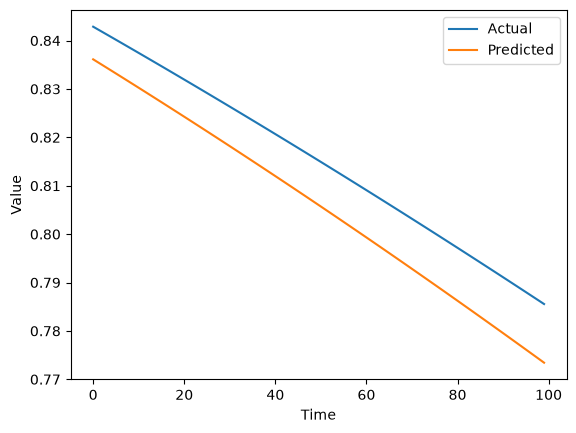

In [26]:


for i, (x, y) in enumerate(test_ds):
    if i >= 3:
        break
    print('batch: ', i)
    y_pred = model.predict(x)
    plt.plot(y.numpy(), label='Actual')
    plt.plot(y_pred, label='Predicted')
    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.legend()
    plt.show()



In [28]:
## vaos a replicar este tema de multivarintes con ejemplos de datos reales. (en este caso datos del tiempo)


from zipfile import ZipFile
import os
from datetime import datetime
import pandas as pd



uri = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip"
zip_path = keras.utils.get_file(origin=uri, fname="jena_climate_2009_2016.csv.zip")
zip_file = ZipFile(zip_path)
zip_file.extractall()

csv_path = "jena_climate_2009_2016.csv"

df = pd.read_csv(csv_path)

df['Date Time'] = pd.to_datetime(
    df['Date Time'],
    format='%d.%m.%Y %H:%M:%S'
)

df.head()



,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,2009-01-01 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,2009-01-01 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,2009-01-01 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,2009-01-01 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,2009-01-01 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


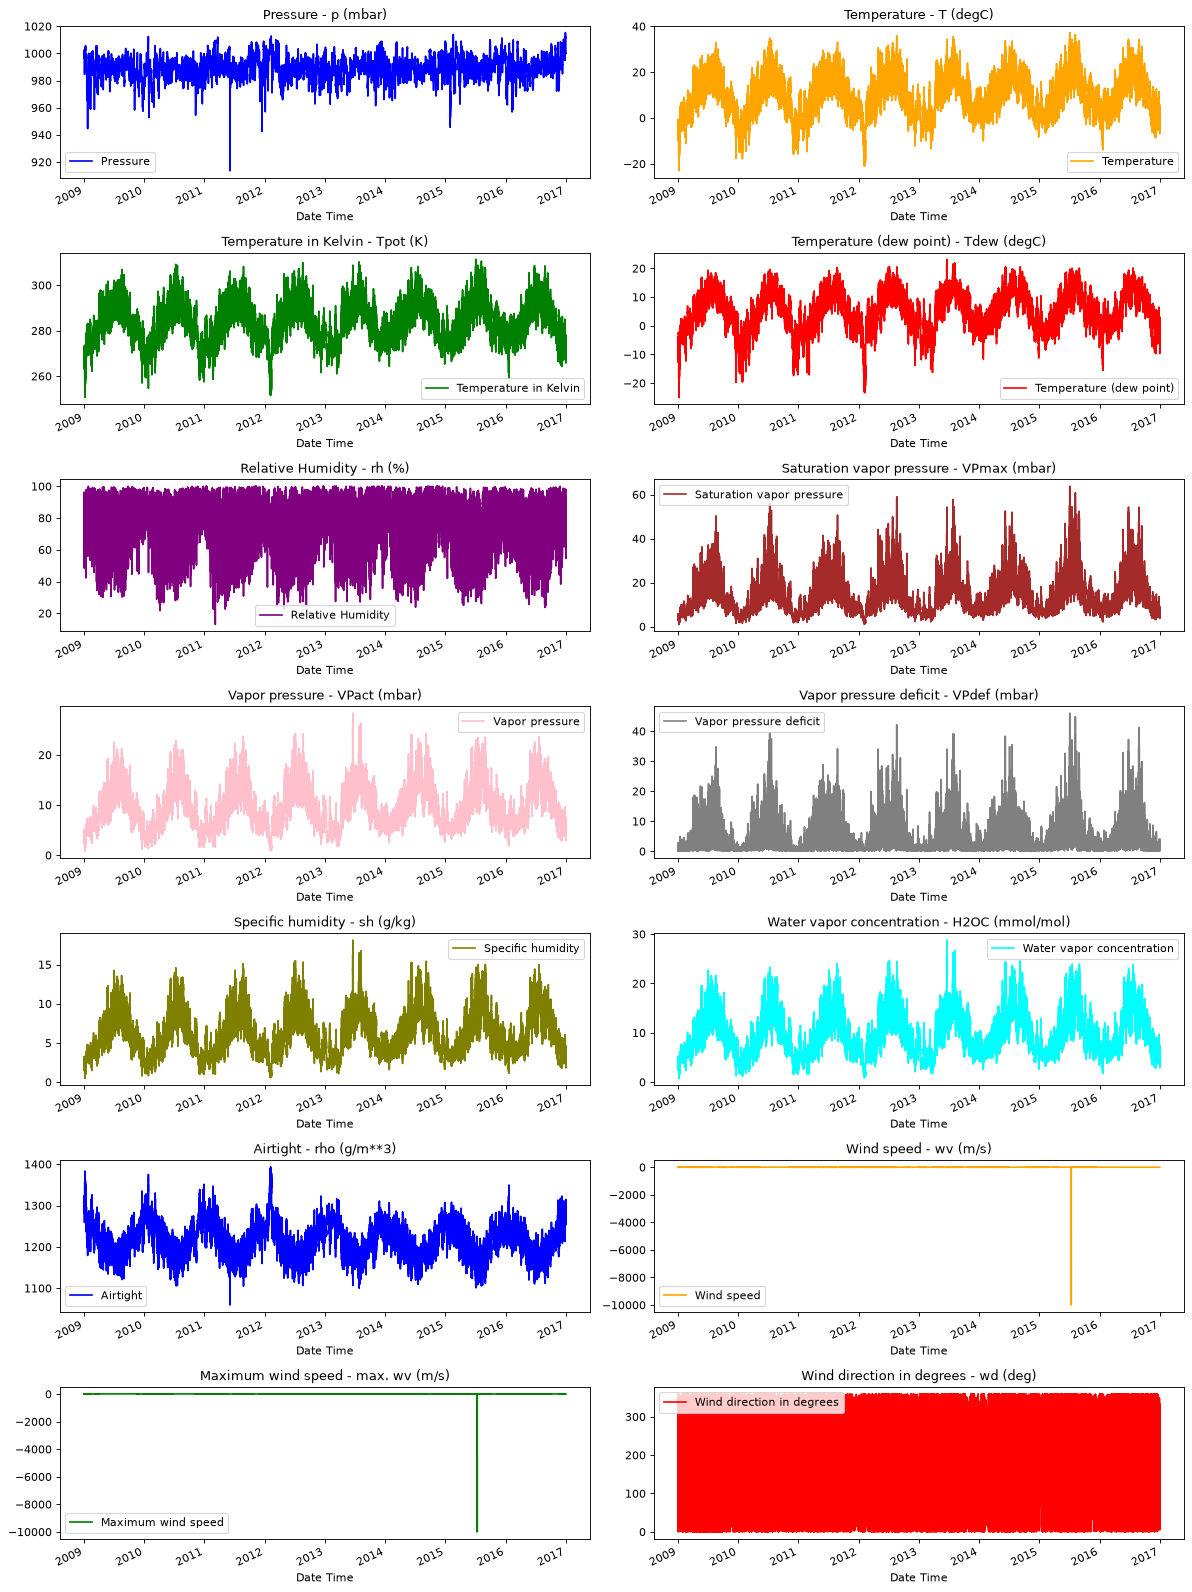

In [29]:


titles = [
    "Pressure",
    "Temperature",
    "Temperature in Kelvin",
    "Temperature (dew point)",
    "Relative Humidity",
    "Saturation vapor pressure",
    "Vapor pressure",
    "Vapor pressure deficit",
    "Specific humidity",
    "Water vapor concentration",
    "Airtight",
    "Wind speed",
    "Maximum wind speed",
    "Wind direction in degrees",
]

feature_keys = [
    "p (mbar)",
    "T (degC)",
    "Tpot (K)",
    "Tdew (degC)",
    "rh (%)",
    "VPmax (mbar)",
    "VPact (mbar)",
    "VPdef (mbar)",
    "sh (g/kg)",
    "H2OC (mmol/mol)",
    "rho (g/m**3)",
    "wv (m/s)",
    "max. wv (m/s)",
    "wd (deg)",
]

colors = [
    "blue",
    "orange",
    "green",
    "red",
    "purple",
    "brown",
    "pink",
    "gray",
    "olive",
    "cyan",
]

date_time_key = "Date Time"


def show_raw_visualization(data):
    time_data = data[date_time_key]
    fig, axes = plt.subplots(
        nrows=7, ncols=2, figsize=(15, 20), dpi=80, facecolor="w", edgecolor="k"
    )
    for i in range(len(feature_keys)):
        key = feature_keys[i]
        c = colors[i % (len(colors))]
        t_data = data[key]
        t_data.index = time_data
        t_data.head()
        ax = t_data.plot(
            ax=axes[i // 2, i % 2],
            color=c,
            title="{} - {}".format(titles[i], key),
            rot=25,
        )
        ax.legend([titles[i]])
    plt.tight_layout()


show_raw_visualization(df)



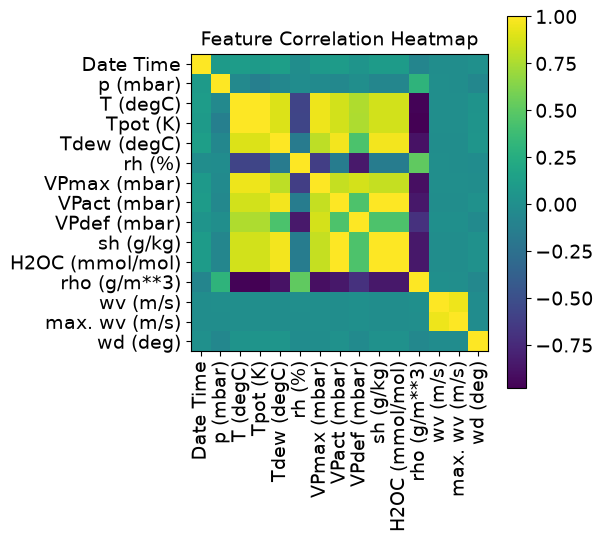

In [30]:


def show_heatmap(data):
    plt.matshow(data.corr())
    plt.xticks(range(data.shape[1]), data.columns, fontsize=14, rotation=90)
    plt.gca().xaxis.tick_bottom()
    plt.yticks(range(data.shape[1]), data.columns, fontsize=14)

    cb = plt.colorbar()
    cb.ax.tick_params(labelsize=14)
    plt.title("Feature Correlation Heatmap", fontsize=14)
    plt.show()


show_heatmap(df)



In [31]:
selected_features_title = ['Pressure', 'Temperature', 'Saturation vapor pressure',
                 'Vapor pressure deficit', 'Specific' 'humidity', 'Airtight', 'Wind speed']
selected_features = ['p (mbar)',
 'T (degC)',
 'VPmax (mbar)',
 'VPdef (mbar)',
 'sh (g/kg)',
 'rho (g/m**3)',
 'wv (m/s)',
"max. wv (m/s)","wd (deg)" ]

In [34]:
#Use only important features
df_0 = df.copy()
df = df[selected_features].copy()


In [ ]:
df.values.shape

(420551, 9)

In [36]:
# train - test
split_fraction = 0.7
train_split = int(split_fraction * int(len(df)))

train_data = df.iloc[0 : train_split]
val_data = df.iloc[train_split:]
train_data.head()

,p (mbar),T (degC),VPmax (mbar),VPdef (mbar),sh (g/kg),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
Date Time,,,,,,,,,
2009-01-01 00:10:00,996.52,-8.02,3.33,0.22,1.94,1307.75,1.03,1.75,152.3
2009-01-01 00:20:00,996.57,-8.41,3.23,0.21,1.89,1309.80,0.72,1.50,136.1
2009-01-01 00:30:00,996.53,-8.51,3.21,0.20,1.88,1310.24,0.19,0.63,171.6
2009-01-01 00:40:00,996.51,-8.31,3.26,0.19,1.92,1309.19,0.34,0.50,198.0
2009-01-01 00:50:00,996.51,-8.27,3.27,0.19,1.92,1309.00,0.32,0.63,214.3


In [37]:
## previous hours to consider
window_size = 6 
## Number of hours later to predict
horizon = 12

batch_size = 128

columns = df.columns
# Get the target column index
target_col_idx = columns.get_loc('T (degC)')

dataset_train = create_windows_multivariate_tf(
    train_data, window_size, horizon, target_col_idx=target_col_idx, shuffle=True)

dataset_val = create_windows_multivariate_tf(
    val_data, window_size, horizon, target_col_idx=target_col_idx, shuffle=False)

dataset_train = dataset_train.batch(batch_size)
dataset_val = dataset_val.batch(500)


for batch in dataset_train.take(1):
    inputs, targets = batch
    break

print("Input shape:", inputs.numpy().shape)
print("Target shape:", targets.numpy().shape)
inputs_shape = (inputs.shape[1], inputs.shape[2])

I0000 00:00:1794216575.803135   38926 shuffle_dataset_op.cc:465] ShuffleDatasetV3:65420: Filling up shuffle buffer (this may take a while): 141901 of 294385


Input shape: (128, 6, 9)
Target shape: (128,)


I0000 00:00:1794216586.281133   38926 shuffle_dataset_op.cc:495] Shuffle buffer filled.


In [38]:
AUTOTUNE = tf.data.AUTOTUNE
dataset_train = dataset_train.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
dataset_val = dataset_val.cache().prefetch(buffer_size=AUTOTUNE)

In [41]:
norm = tf.keras.layers.Normalization(  ## esto lo estamos haciendo con keras pero lo podemos hacer con muchas otras cosas
    axis=-1, dtype=None, mean=None, variance=None
)
norm.adapt(dataset_train.map(lambda x, y: x))

print('Unnormalized row: ', df.iloc[:1].values)
print('Normalized row: ', norm(df.iloc[:1]))
print('Normalized df, mean row: ',norm(df.values).numpy().mean(1))
print('Normalized df, std row: ',np.std(norm(df.values).numpy(), 1))

I0000 00:00:1794216728.491156   39214 shuffle_dataset_op.cc:465] ShuffleDatasetV3:65420: Filling up shuffle buffer (this may take a while): 144820 of 294385
I0000 00:00:1794216739.172206   39214 shuffle_dataset_op.cc:495] Shuffle buffer filled.
I0000 00:00:1794216739.172617   39214 shuffle_dataset_op.cc:465] ShuffleDatasetV3:654165: Filling up shuffle buffer (this may take a while): 1 of 1000


     51/Unknown 21s 3ms/step

I0000 00:00:1794216739.382011   39214 shuffle_dataset_op.cc:495] Shuffle buffer filled.


   2300/Unknown 29s 3ms/step
Unnormalized row:  [[ 9.96520e+02 -8.02000e+00  3.33000e+00  2.20000e-01  1.94000e+00
   1.30775e+03  1.03000e+00  1.75000e+00  1.52300e+02]]
Normalized row:  tf.Tensor(
[[[ 0.9476617  -1.9790853  -1.303048   -0.78450423 -1.4872575
    2.2158227  -0.73498315 -0.7824673  -0.24110313]]], shape=(1, 1, 9), dtype=float32)
Normalized df, mean row:  [[ 0.06695044  0.03960022  0.02887451  0.00927535  0.04091162 -0.02282291
  -0.29566103 -0.21788234  0.01488926]]
Normalized df, std row:  [[ 1.0073401   0.97323966  1.0059401   1.0168644   0.99423224  0.9759543
  42.76968    29.82034     0.98863083]]


In [44]:
norm = tf.keras.layers.Normalization(
    axis=-1
)
norm.adapt(dataset_train.map(lambda x, y: x))

num_features =  9
inputs_shape = (window_size, num_features)

inputs = keras.layers.Input(shape=inputs_shape)
inputs_norm = norm(inputs)
rnn_out = keras.layers.SimpleRNN(32)(inputs_norm)
outputs = keras.layers.Dense(1)(rnn_out)

model = keras.Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=keras.optimizers.Adam(), loss="mse")
model.summary()

   2300/Unknown 8s 3ms/step


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 6, 9)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization_1 (Normalization) │ (None, 6, 9)           │            19 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,396 (5.46 KB)

 Trainable params: 1,377 (5.38 KB)

 Non-trainable params: 19 (80.00 B)

In [47]:
path_checkpoint = "model_checkpoint.weights.h5"
es_callback = keras.callbacks.EarlyStopping(
    monitor="val_loss", min_delta=0, patience=3)

modelckpt_callback = keras.callbacks.ModelCheckpoint(
    monitor="val_loss",
    filepath=path_checkpoint,
    verbose=1,
    save_weights_only=True,
    save_best_only=True,
)

history = model.fit(
    dataset_train,
    epochs=25,
    validation_data=dataset_val,
    callbacks=[es_callback, modelckpt_callback],
)

Epoch 1/25


/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1794216850.213665   31986 service.cc:154] XLA service 0x5711ccd8f540 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794216850.213696   31986 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 2060, Compute Capability 7.5 (Driver: 13.0.0[580.178.4]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1794216850.253410   31986 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


     63/Unknown 1s 2ms/step - loss: 127.2195

I0000 00:00:1794216850.832784   31986 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


   2294/Unknown 8s 3ms/step - loss: 12.0074
Epoch 1: val_loss improved from None to 2.91984, saving model to model_checkpoint.weights.h5

Epoch 1: finished saving model to model_checkpoint.weights.h5
2300/2300 ━━━━━━━━━━━━━━━━━━━━ 17s 7ms/step - loss: 11.9828 - val_loss: 2.9198
Epoch 2/25
2300/2300 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.2931
Epoch 2: val_loss improved from 2.91984 to 2.12828, saving model to model_checkpoint.weights.h5

Epoch 2: finished saving model to model_checkpoint.weights.h5
2300/2300 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 2.2931 - val_loss: 2.1283
Epoch 3/25
2296/2300 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.9993
Epoch 3: val_loss improved from 2.12828 to 1.93521, saving model to model_checkpoint.weights.h5

Epoch 3: finished saving model to model_checkpoint.weights.h5
2300/2300 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 1.9986 - val_loss: 1.9352
Epoch 4/25
2299/2300 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.9093
Epoch 4: val_loss did not improve from 1.9

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


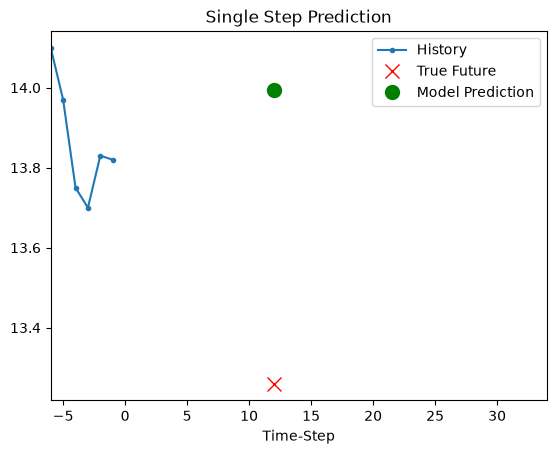

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


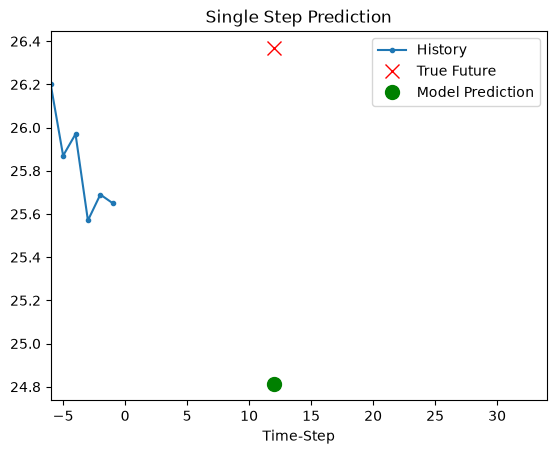

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


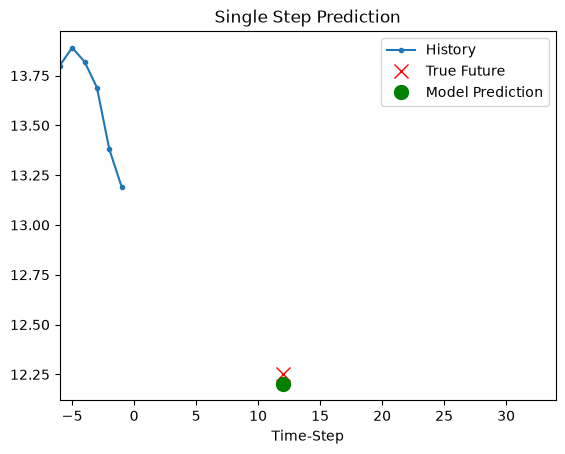

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


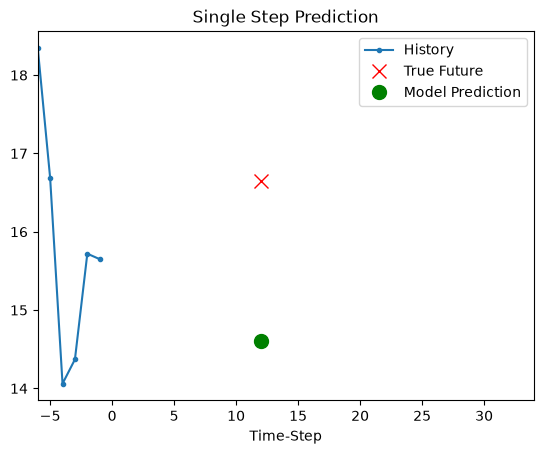

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


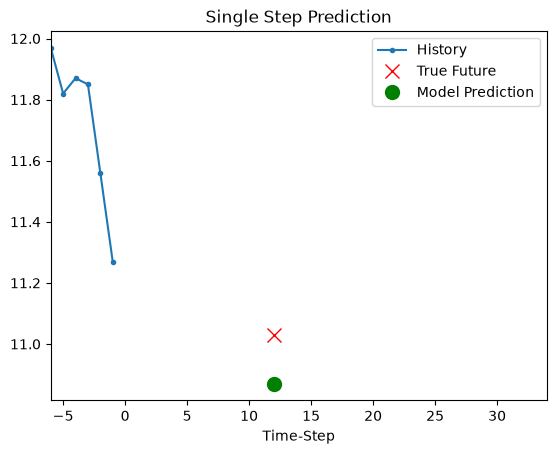

In [50]:
def show_plot(plot_data, delta, title):
    labels = ["History", "True Future", "Model Prediction"]
    marker = [".-", "rx", "go"]
    time_steps = list(range(-(plot_data[0].shape[0]), 0))
    if delta:
        future = delta
    else:
        future = 0

    plt.title(title)
    for i, val in enumerate(plot_data):
        if i:
            plt.plot(future, plot_data[i], marker[i], markersize=10, label=labels[i])
        else:
            plt.plot(time_steps, plot_data[i].flatten(), marker[i], label=labels[i])
    plt.legend()
    plt.xlim([time_steps[0], (future + 5) * 2])
    plt.xlabel("Time-Step")
    plt.show()
    return

for x, y in dataset_val.take(5):
    show_plot(
        [x[0][:, 1].numpy(), y[0].numpy(), model.predict(x)[0]],
        horizon,
        "Single Step Prediction",
    )

batch:  0
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


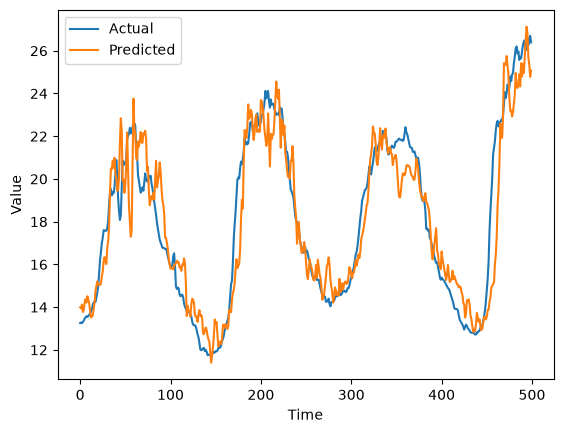

batch:  1
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


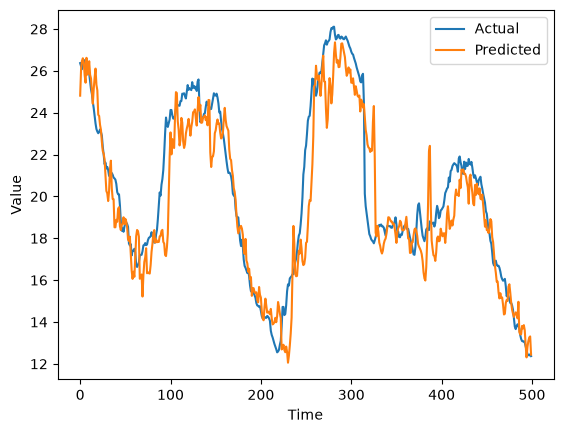

batch:  2
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


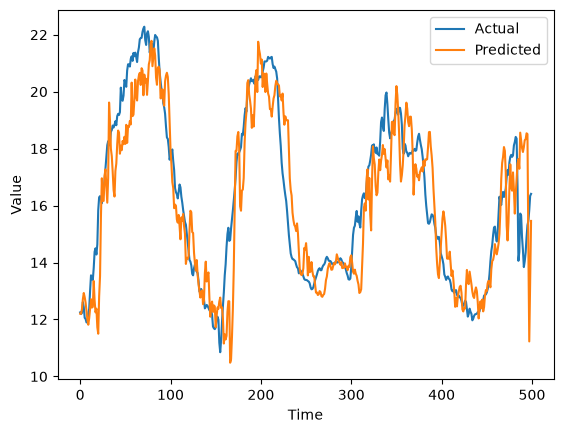

In [49]:


for i, (x, y) in enumerate(dataset_val):
    if i >= 3:
        break
    print('batch: ', i)
    y_pred = model.predict(x)
    plt.plot(y.numpy(), label='Actual')
    plt.plot(y_pred, label='Predicted')
    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.legend()
    plt.show()



In [1]:
# comprobaciones de uso de GPU
import tensorflow as tf

print("TensorFlow:", tf.__version__)

gpus = tf.config.list_physical_devices('GPU')

if gpus:
    print("GPU detectada:")
    for gpu in gpus:
        print(gpu)
else:
    print("No se han detectado GPUs. Se utilizará CPU.")

I0000 00:00:1794214235.988212   31986 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.22.0-rc0
GPU detectada:
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
